In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("smartcart_customers.csv")

In [4]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [6]:
df.shape

(2240, 22)

DATA PREPROCESSING


In [7]:
#handling missing values

In [8]:
df["Income"]=df["Income"].fillna(df["Income"].median())

FEATURE ENGINEERING



In [9]:
df["Age"]=2026-df["Year_Birth"]

In [10]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age'],
      dtype='object')

In [11]:
print(df["Age"])

0       69
1       72
2       61
3       42
4       45
        ..
2235    59
2236    80
2237    45
2238    70
2239    72
Name: Age, Length: 2240, dtype: int64


In [12]:
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"],dayfirst=True,errors='coerce')

Reference_Date=df["Dt_Customer"].max()

df["Customer_tenure_Days"]=(Reference_Date-df["Dt_Customer"]).dt.days

In [13]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_tenure_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [14]:
df.columns


Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_tenure_Days'],
      dtype='object')

In [15]:
#spendings
df["Total_Spending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]
+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntSweetProducts"]

0       348
1         4
2       153
3        16
4       100
       ... 
2235    278
2236      0
2237     56
2238    140
2239      4
Length: 2240, dtype: int64

In [16]:
df["Total_Children"]=df["Kidhome"]+df["Teenhome"]

In [17]:
df["Education"].replace({
    "Basic":"Undergraduate","2nCycle":"Undergraduate",
    "PhD":"PostGraduate","Master":"PostGraduate",
    "Graduation":"Graduate"})
    

0           Graduate
1           Graduate
2           Graduate
3           Graduate
4       PostGraduate
            ...     
2235        Graduate
2236    PostGraduate
2237        Graduate
2238    PostGraduate
2239    PostGraduate
Name: Education, Length: 2240, dtype: object

In [18]:
#martial status
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [19]:
df["Living_With"]=df["Marital_Status"].replace({
    "Married":"Partner","Together":"Partner",
    "Single":"Alone","Divorced":"Alone",
    "Widow":"Alone","Absurd":"Alone",
    "YOLO":"Alone",})

##Droping columns

In [20]:
cols=["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]
spending_cols=["MntWines", "MntFruits",
       "MntMeatProducts", "MntFishProducts", "MntSweetProducts",
       "MntGoldProds"]
cols_to_drop=cols+spending_cols

df_cleaned=df.drop(columns=cols_to_drop)

In [21]:
df.shape

(2240, 27)

In [22]:
df_cleaned.shape

(2240, 15)

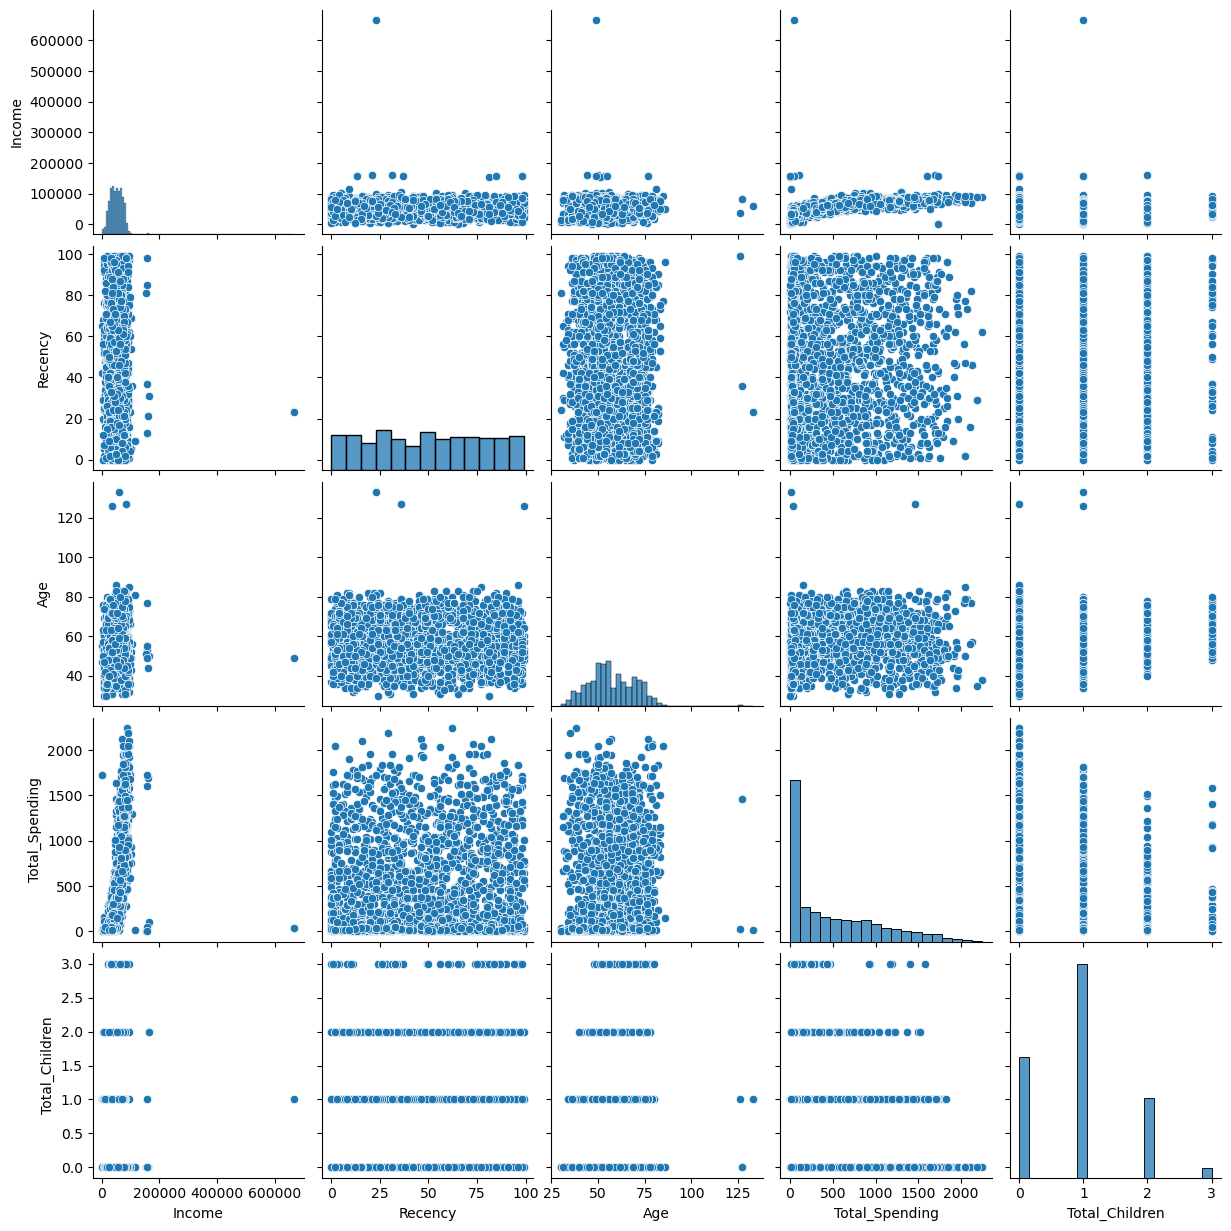

In [24]:
import seaborn as sns
#to find the outlierss
cols=["Income","Recency","Age","Total_Spending","Total_Children"]
sns.pairplot(df_cleaned[cols])

In [27]:
df_cleaned=df_cleaned[(df_cleaned["Age"]<90)]
df_cleaned=df_cleaned[(df_cleaned["Income"]<600_000)]

HEATMAP

In [35]:
corr=df_cleaned.corr(numeric_only=True)
plt.figure(figsize=(8,6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Axes: >

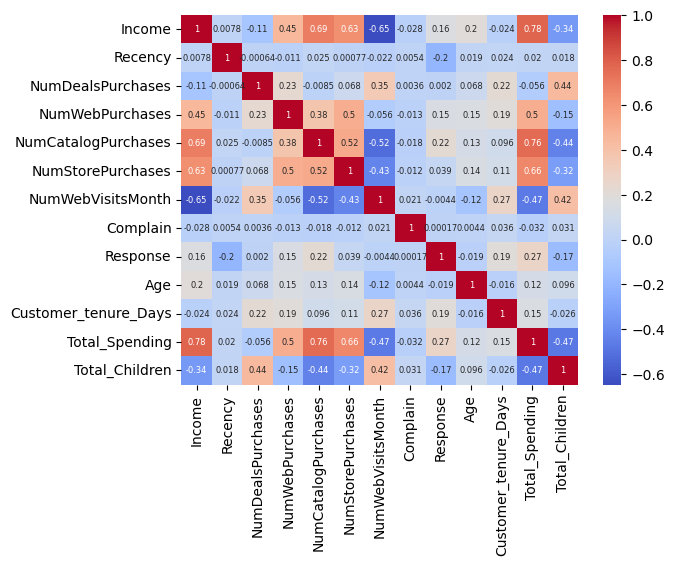

In [36]:
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)